In [18]:
# Import the libraries needed for Micro-Project 2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [19]:
# Load the prepared Adult Income dataset from Micro-Project 1
df = pd.read_csv("adult_income_prepared.csv")

# Verify the dataset dimensions and display the first five rows
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (32537, 8)


,age,education,education_num,workclass,occupation,hours_per_week,marital_status,income
0,39,Bachelors,13,State-gov,Adm-clerical,40,Never-married,<=50K
1,50,Bachelors,13,Self-emp-not-inc,Exec-managerial,13,Married-civ-spouse,<=50K
2,38,HS-grad,9,Private,Handlers-cleaners,40,Divorced,<=50K
3,53,11th,7,Private,Handlers-cleaners,40,Married-civ-spouse,<=50K
4,28,Bachelors,13,Private,Prof-specialty,40,Married-civ-spouse,<=50K


In [20]:
# Check the number of records in each income category
income_counts = df["income"].value_counts()

# Calculate the percentage of the dataset in each income category
income_percent = df["income"].value_counts(normalize=True) * 100

print("Income Category Counts:")
print(income_counts)

print("\nIncome Category Percentages:")
print(income_percent.round(2))

Income Category Counts:
income
<=50K    24698
>50K      7839
Name: count, dtype: int64

Income Category Percentages:
income
<=50K    75.91
>50K     24.09
Name: proportion, dtype: float64


In [21]:
# Use NumPy to examine the distribution of weekly work hours
hours = df["hours_per_week"].to_numpy()

print("Weekly Work Hours Summary:")
print("Mean:", np.round(np.mean(hours), 2))
print("Median:", np.median(hours))
print("Minimum:", np.min(hours))
print("Maximum:", np.max(hours))

# Calculate selected percentiles to help identify unusual values
percentiles = np.percentile(hours, [25, 50, 75, 95])

print("\nWork Hours Percentiles:")
print("25th percentile:", percentiles[0])
print("50th percentile:", percentiles[1])
print("75th percentile:", percentiles[2])
print("95th percentile:", percentiles[3])

Weekly Work Hours Summary:
Mean: 40.44
Median: 40.0
Minimum: 1
Maximum: 99

Work Hours Percentiles:
25th percentile: 40.0
50th percentile: 40.0
75th percentile: 45.0
95th percentile: 60.0


In [22]:
# Investigate unusually high weekly work-hour values
high_hours = df[df["hours_per_week"] > 60]

print("Records with more than 60 work hours per week:")
print(len(high_hours))

print("\nPercentage of dataset:")
print(round((len(high_hours) / len(df)) * 100, 2))

# Review the distribution of these higher values
print("\nHigh Work-Hour Distribution:")
print(high_hours["hours_per_week"].value_counts().sort_index())

Records with more than 60 work hours per week:
1110

Percentage of dataset:
3.41

High Work-Hour Distribution:
hours_per_week
61      2
62     18
63     10
64     14
65    244
66     17
67      4
68     12
70    291
72     71
73      2
74      1
75     66
76      3
77      6
78      8
80    133
81      3
82      1
84     45
85     13
86      2
87      1
88      2
89      2
90     29
91      3
92      1
94      1
95      2
96      5
97      2
98     11
99     85
Name: count, dtype: int64


In [23]:
# Examine the distribution of important categorical variables
categorical_columns = ["education", "workclass", "occupation", "marital_status"]

for column in categorical_columns:
    print("\n", column.upper())
    print(df[column].value_counts())


 EDUCATION
education
HS-grad         10494
Some-college     7282
Bachelors        5353
Masters          1722
Assoc-voc        1382
11th             1175
Assoc-acdm       1067
10th              933
7th-8th           645
Prof-school       576
9th               514
12th              433
Doctorate         413
5th-6th           332
1st-4th           166
Preschool          50
Name: count, dtype: int64

 WORKCLASS
workclass
Private             24509
Self-emp-not-inc     2540
Local-gov            2093
State-gov            1298
Self-emp-inc         1116
Federal-gov           960
Without-pay            14
Never-worked            7
Name: count, dtype: int64

 OCCUPATION
occupation
Prof-specialty       5979
Craft-repair         4094
Exec-managerial      4065
Adm-clerical         3768
Sales                3650
Other-service        3291
Machine-op-inspct    2000
Transport-moving     1597
Handlers-cleaners    1369
Farming-fishing       992
Tech-support          927
Protective-serv       649
Priv-hou

In [24]:
# Review the most common workclass and occupation values
# These fields had unknown values filled with the mode during Micro-Project 1

print("Most Common Workclass Values:")
print(df["workclass"].value_counts().head())

print("\nMost Common Occupation Values:")
print(df["occupation"].value_counts().head())

Most Common Workclass Values:
workclass
Private             24509
Self-emp-not-inc     2540
Local-gov            2093
State-gov            1298
Self-emp-inc         1116
Name: count, dtype: int64

Most Common Occupation Values:
occupation
Prof-specialty     5979
Craft-repair       4094
Exec-managerial    4065
Adm-clerical       3768
Sales              3650
Name: count, dtype: int64


In [25]:
# Review descriptive statistics for the main numerical variables
numerical_columns = ["age", "education_num", "hours_per_week"]

print("Numerical Variable Distributions:")
print(df[numerical_columns].describe())

Numerical Variable Distributions:
                age  education_num  hours_per_week
count  32537.000000   32537.000000    32537.000000
mean      38.585549      10.081815       40.440329
std       13.637984       2.571633       12.346889
min       17.000000       1.000000        1.000000
25%       28.000000       9.000000       40.000000
50%       37.000000      10.000000       40.000000
75%       48.000000      12.000000       45.000000
max       90.000000      16.000000       99.000000


In [26]:
# Calculate average weekly work hours for each income group
average_hours = df.groupby("income")["hours_per_week"].mean()

print("Average Weekly Work Hours by Income Group:")
print(average_hours.round(2))

Average Weekly Work Hours by Income Group:
income
<=50K    38.84
>50K     45.47
Name: hours_per_week, dtype: float64


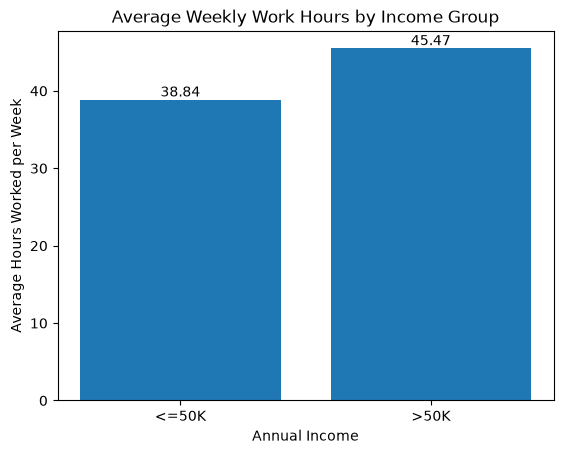

In [27]:
# Create a bar chart comparing average weekly work hours by income group
bars = plt.bar(average_hours.index, average_hours.values)

# Add a clear title and labels for a nontechnical audience
plt.title("Average Weekly Work Hours by Income Group")
plt.xlabel("Annual Income")
plt.ylabel("Average Hours Worked per Week")

# Display the average value above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}",
        ha="center",
        va="bottom"
    )

## Step 4: Report

The purpose of this visualization was to compare average weekly work hours between the two income categories for a nontechnical audience. Individuals earning \$50,000 or less worked an average of 38.84 hours per week, while individuals earning more than \$50,000 worked an average of 45.47 hours per week. This is a difference of approximately 6.63 hours per week.

The results support the work-hours portion of the hypothesis because the higher-income group worked more hours per week on average. However, this is an association and does not establish that working more hours causes higher income. Education, occupation, work class, and other characteristics may also contribute to differences between the income groups.

The preparation review also identified limitations that should be considered in later analysis. Unknown workclass and occupation values were previously replaced with the mode, which may increase the frequency of the most common categories. The 24 repeated records were also removed during the earlier preparation process. These decisions should be justified and investigated further before predictive modeling because they could affect the distribution of the data.

Micro-Project 2 concludes at Step 4: Report.